# Bayesian Sheaf Neural Networks

Every sheaf model so far has learned **one** sheaf: a single restriction map per incidence. On small, noisy, or heterophilic graphs, many different sheaves explain the training labels almost equally well, and committing to one of them hides that ambiguity. **Bayesian Sheaf Neural Networks** (BSNN; Gillespie et al., 2025) instead learn a **distribution** over restriction maps. Every forward pass samples a fresh sheaf, the model is trained with a variational objective (the ELBO), and predictions come with an estimate of their own uncertainty.

### What You Will Learn
* How the repository parameterizes posteriors over diagonal, general, low-rank, and orthogonal restriction maps.
* The ELBO objective, the reparameterization trick, and the cyclical KL annealing schedule used by the reference implementation.
* The difference between **aleatoric** and **epistemic** uncertainty, and how predictive entropy, epistemic variance, and mutual information separate them.
* How to check whether a model's uncertainty is *useful*: errors, selective prediction, corrupted inputs, calibration, and the posterior over the maps themselves.

### Notebook Roadmap
1. **Motivate** distributions over sheaves.
2. **Formalize** the variational sheaf learner, the ELBO, and the uncertainty measures.
3. **Build** a heterophilic toy graph.
4. **Train** a BSNN with the repository's ELBO schedule, next to a deterministic NSD.
5. **Interpret** the predictive uncertainty and the posterior over restriction maps.

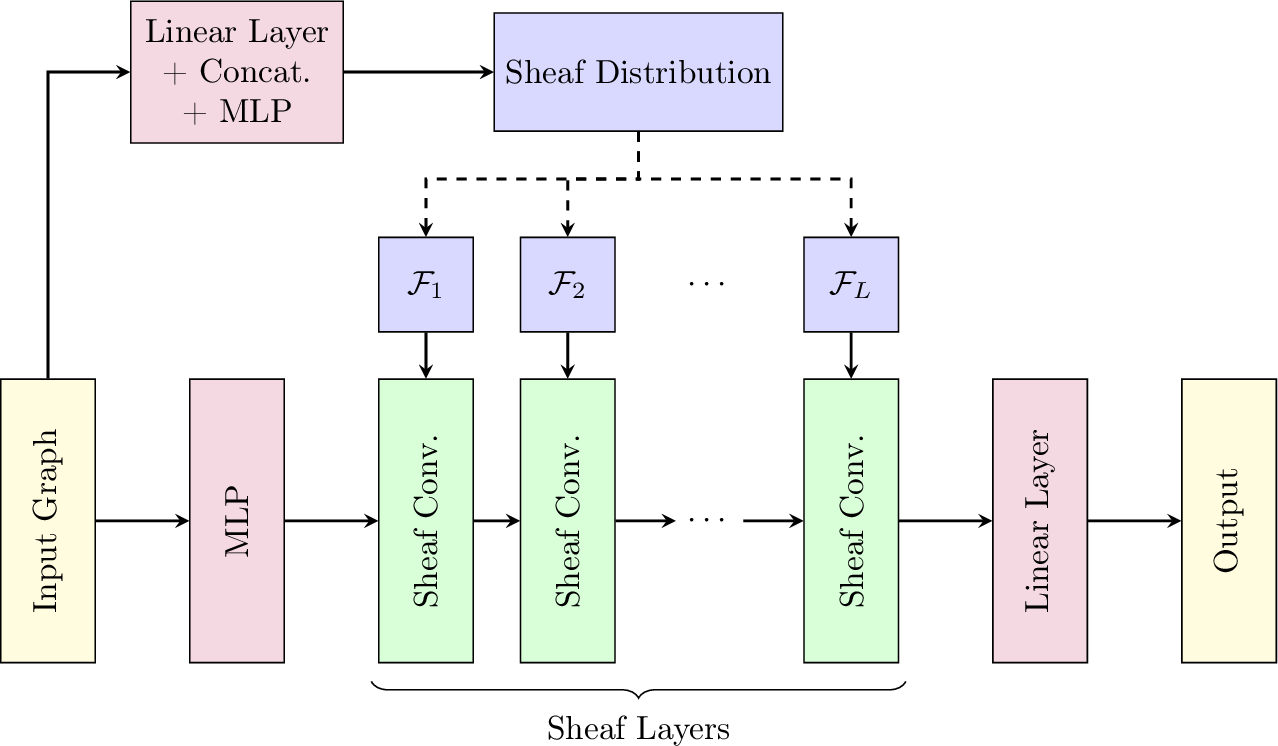

*The BSNN architecture. A variational sheaf learner (top) maps pairs of node features to the parameters of a distribution over restriction maps; every sheaf convolution layer receives its own sampled sheaf F_1, ..., F_L (dashed arrows), while the feature pipeline (bottom) is the usual encoder, sheaf layers, and linear decoder.*

<sub>Source: Gillespie et al. (2025), *Bayesian Sheaf Neural Networks*, [arXiv:2410.09590](https://arxiv.org/abs/2410.09590), Fig. 2. Reproduced for teaching with attribution (CC BY-NC-SA 4.0).</sub>

## Table of Contents

1. [Introduction](#1-introduction)
2. [Environment Setup and Imports](#2-env-setup)
3. [Variational Sheaves](#3-variational-sheaves)
    * [Posteriors over Restriction Maps](#posteriors)
    * [The ELBO and KL Annealing](#elbo)
    * [Two Kinds of Uncertainty](#uncertainty-kinds)
4. [Dataset Pipeline](#4-dataset-pipeline)
5. [Model Construction](#5-model-construction)
6. [Training with the ELBO](#6-training)
7. [Interpreting Bayesian Sheaves](#7-interpretation)
    * [Uncertainty on Test Nodes](#test-uncertainty)
    * [Is the Uncertainty Useful?](#useful-uncertainty)
    * [Corrupted Inputs](#corrupted-inputs)
    * [The Posterior over Restriction Maps](#posterior-maps)
    * [How Many Samples?](#how-many-samples)
8. [Configuration, Reproducibility, and Exercises](#8-exercises)

<a id="1-introduction"></a>
# 1. Introduction

A deterministic sheaf learner maps a pair of node features to *the* restriction map of an edge. Training picks the maps that minimize the loss, and nothing in the model records how confident it is in them. Two problems follow:
* **Overfitting the geometry.** With few labels, the maps can memorize the training nodes. The resulting sheaf is sharp but wrong elsewhere.
* **No sense of doubt.** A softmax output is not an uncertainty estimate. Deterministic networks are often confidently wrong, especially on nodes unlike the training data.

BSNN treats the sheaf $\mathcal{F}$ as a **latent random variable**. A variational posterior $q_\phi(\mathcal{F} \mid \mathbf{X}, \mathcal{G})$ is predicted from the features and regularized towards a prior $p(\mathcal{F})$. During training, every forward pass samples restriction maps from $q_\phi$. At test time, many samples are averaged into a predictive distribution whose spread measures the model's uncertainty about the geometry.

<a id="2-env-setup"></a>
# 2. Environment Setup and Imports

Use the repository's Python 3.13 environment (`uv sync`) and run the notebook top to bottom from a fresh kernel. Everything runs on CPU in about two minutes.

In [1]:
# =====================================================================
# 1. Standard Library & Repository Path
# =====================================================================
import copy
import random
import sys
import warnings
from pathlib import Path


def find_repo_root(start: Path | None = None) -> Path:
    """Find the repository root (the folder holding pyproject.toml and src/)."""
    start = (start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "src").exists():
            return p
    raise FileNotFoundError("Could not locate the repository")


REPO_ROOT = find_repo_root()
SRC_PATH = REPO_ROOT / "src"
if str(SRC_PATH) not in sys.path:
    sys.path.insert(0, str(SRC_PATH))

# =====================================================================
# 2. Core Scientific Libraries
# =====================================================================
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch_geometric.data import Data

# =====================================================================
# 3. Reproducibility
# =====================================================================
warnings.filterwarnings("ignore")
SEED = 42


def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)  # noqa: NPY002
    torch.manual_seed(seed)


set_seed(SEED)
torch.set_num_threads(1)  # small graphs: avoid thread overhead and nondeterminism

print("--- Environment Status ---")
print(f"Repository root: {REPO_ROOT}")
print(f"Python:  {sys.version.split()[0]}")
print(f"PyTorch: {torch.__version__}")

# =====================================================================
# 4. Repository-Specific Modules
# =====================================================================
from torch_geometric.utils import homophily, stochastic_blockmodel_graph

from sheaf_mpnn.bsnn import BSNNModel, BSNNVariant
from sheaf_mpnn.bsnn.bsnn_model import reverse_edge_permutation
from sheaf_mpnn.bsnn.uncertainty import (
    epistemic_variance,
    expected_calibration_error,
    mutual_information,
    predictive_entropy,
)
from sheaf_mpnn.nsd import NSDModel, NSDVariant

print("Loaded BSNNModel, its uncertainty metrics, and the NSD baseline.")

--- Environment Status ---
Repository root: <repo>
Python:  3.13.12
PyTorch: 2.8.0
Loaded BSNNModel, its uncertainty metrics, and the NSD baseline.


<a id="3-variational-sheaves"></a>
# 3. Variational Sheaves

<a id="posteriors"></a>
### 3.1 Posteriors over Restriction Maps

The variational sheaf learner (`sheaf_mpnn/bsnn/variational.py`) computes the posterior parameters **once** per forward pass from the lifted node features, with two linear heads (a mean and a scale) applied to the concatenated endpoint features of every incidence. Each restriction-map family has its own posterior:

| Variant | Posterior over each map | Prior |
|---|---|---|
| `DIAGONAL` | independent Gaussians on the $d$ diagonal entries, mean $\tanh(\mu)$ | $\mathcal{N}(0, 1)$ |
| `GENERAL` | independent Gaussians on all $d^2$ entries | $\mathcal{N}(0, 1)$ |
| `LOW_RANK` | Gaussians on the two rank-$r$ factors | $\mathcal{N}(0, 1)$ |
| `ORTHOGONAL` | a distribution over rotations, sampled via the Cayley transform | as in the paper |

Samples use the **reparameterization trick**: for the diagonal case, $\mathbf{w} = \tanh(\boldsymbol{\mu}) + \boldsymbol{\sigma} \odot \boldsymbol{\epsilon}$ with $\boldsymbol{\epsilon} \sim \mathcal{N}(0, I)$, so gradients flow through $\boldsymbol{\mu}$ and $\boldsymbol{\sigma}$. Every layer draws its **own independent** sheaf from the shared posterior, as shown in the architecture figure.

<a id="elbo"></a>
### 3.2 The ELBO and KL Annealing

Training maximizes the evidence lower bound, written here as a loss to minimize:

$$\mathcal{L}(\phi, \theta) = \underbrace{\mathbb{E}_{\mathcal{F} \sim q_\phi}\Big[-\sum_{u \in \text{train}} \log p_\theta(y_u \mid \mathbf{X}, \mathcal{F})\Big]}_{\text{cross-entropy on a sampled sheaf}} \;+\; \beta_t\, \underbrace{\mathrm{KL}\big(q_\phi(\mathcal{F}) \,\|\, p(\mathcal{F})\big)}_{\text{stay close to the prior}}.$$

The expectation is estimated with one sample per step. The KL term (averaged over incident pairs by `model.kl_loss()`) pulls the posterior towards the prior, which keeps the maps from becoming over-confident. Turning it on at full strength from the start tends to *collapse* the posterior onto the prior before the data has shaped it. The reference implementation therefore uses **cyclical annealing** (Fu et al., 2019): every 40 epochs, $\beta_t$ ramps from 0 to 1 along a sigmoid,

$$\beta_t = \sigma\big(20\, \tfrac{t \bmod 40}{40} - 10\big).$$

The repository's `BayesSheafLightningModule.kl_beta` implements exactly this, with `--model.kl-weight`, `--model.kl-cycle`, and `--model.kl-anneal` as knobs.

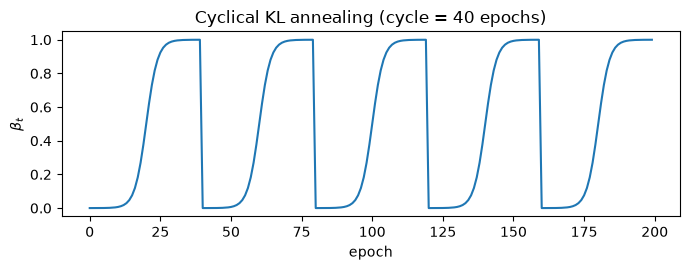

In [2]:
# =====================================================================
# The cyclical KL schedule of the reference BSNN
# =====================================================================
def kl_beta(epoch: int, weight: float = 1.0, cycle: int = 40) -> float:
    frac = (epoch % cycle) / cycle
    return weight * torch.sigmoid(torch.tensor(20.0 * frac - 10.0)).item()


epochs_axis = np.arange(200)
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.plot(epochs_axis, [kl_beta(e) for e in epochs_axis])
ax.set(
    xlabel="epoch",
    ylabel=r"$\beta_t$",
    title="Cyclical KL annealing (cycle = 40 epochs)",
)
plt.tight_layout()
plt.show()

<a id="uncertainty-kinds"></a>
### 3.3 Two Kinds of Uncertainty

With $T$ sampled forward passes $p_t(y \mid u)$ and their mean $\bar{p}(y \mid u)$, the repository's `sheaf_mpnn.bsnn.uncertainty` module implements the paper's measures:
* **Predictive entropy** $H[\bar{p}]$: the *total* uncertainty of the averaged prediction.
* **Epistemic variance**: the class-averaged variance of $p_t$ across samples, i.e. how much the samples *disagree*.
* **Mutual information** $H[\bar{p}] - \tfrac{1}{T}\sum_t H[p_t]$: the part of the total entropy caused by disagreement between samples. This is the **epistemic** (model) uncertainty, which more data could reduce.

The remainder, $\tfrac{1}{T}\sum_t H[p_t]$, is **aleatoric**: every sample is unsure in the same way, so the ambiguity lies in the data itself. The cell below builds two ensembles with the same 50/50 average prediction to show that the measures tell them apart.

In [3]:
# =====================================================================
# Aleatoric vs epistemic: same mean prediction, different ensembles
# =====================================================================
T = 32
aleatoric = torch.full((T, 1, 2), 0.5)  # every sample says 50/50
epistemic = torch.tensor([[[0.98, 0.02]], [[0.02, 0.98]]]).repeat(
    T // 2, 1, 1
)  # confident, but they disagree

print(
    f"{'ensemble':<12}{'mean prob':>14}{'entropy':>10}{'epi. var':>10}{'mutual info':>13}"
)
for name, ens in [("aleatoric", aleatoric), ("epistemic", epistemic)]:
    mean = ens.mean(0)
    print(
        f"{name:<12}{str([round(v, 2) for v in mean[0].tolist()]):>14}"
        f"{predictive_entropy(mean).item():>10.3f}{epistemic_variance(ens).item():>10.3f}"
        f"{mutual_information(ens).item():>13.3f}"
    )
print(
    "\nSame entropy (log 2 = 0.693); only the epistemic measures reveal that the samples disagree."
)

ensemble         mean prob   entropy  epi. var  mutual info
aleatoric       [0.5, 0.5]     0.693     0.000        0.000
epistemic       [0.5, 0.5]     0.693     0.238        0.595

Same entropy (log 2 = 0.693); only the epistemic measures reveal that the samples disagree.


<a id="4-dataset-pipeline"></a>
# 4. Dataset Pipeline

We use a two-class stochastic block model with 160 nodes, average degree 6, and edge homophily around 0.15, with 4 noisy features of which only the first carries a weak class signal. Labels are scarce (40% of the nodes) and neighbourhoods are mostly heterophilic, so many sheaves fit the training labels: a natural setting for a posterior over geometries.

In [4]:
def random_splits(n: int, train: float = 0.4, val: float = 0.2, seed: int = SEED):
    """Disjoint boolean train/val/test masks over n nodes."""
    g = torch.Generator().manual_seed(seed)
    perm = torch.randperm(n, generator=g)
    n_train, n_val = int(train * n), int(val * n)
    masks = [torch.zeros(n, dtype=torch.bool) for _ in range(3)]
    masks[0][perm[:n_train]] = True
    masks[1][perm[n_train : n_train + n_val]] = True
    masks[2][perm[n_train + n_val :]] = True
    return masks


# =====================================================================
# Heterophilic stochastic block model
# =====================================================================
set_seed(SEED)
n, h, avg_degree = 160, 0.15, 6
half = n // 2
p_in, p_out = h * avg_degree / half, (1 - h) * avg_degree / half
edge_index = stochastic_blockmodel_graph([half, half], [[p_in, p_out], [p_out, p_in]])
y = torch.cat([torch.zeros(half), torch.ones(half)]).long()
x = torch.randn(n, 4)
x[:, 0] += 0.7 * (2 * y.float() - 1)
train_mask, val_mask, test_mask = random_splits(n)
data = Data(
    x=x,
    y=y,
    edge_index=edge_index,
    train_mask=train_mask,
    val_mask=val_mask,
    test_mask=test_mask,
)

print("--- Toy graph ---")
print(data)
print(f"Edge homophily: {homophily(edge_index, y, method='edge'):.3f}")
print(
    f"Split sizes (train/val/test): {[int(m.sum()) for m in (train_mask, val_mask, test_mask)]}"
)

--- Toy graph ---
Data(x=[160, 4], edge_index=[2, 930], y=[160], train_mask=[160], val_mask=[160], test_mask=[160])
Edge homophily: 0.157
Split sizes (train/val/test): [64, 32, 64]


<a id="5-model-construction"></a>
# 5. Model Construction

We use the diagonal variant with $d = 2$, two layers, and an evaluation ensemble of 16 samples (`ensemble_size`, used by `predict_proba` when no sample count is given). `kl_loss()` returns the KL divergence of the most recent forward pass.

In [5]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)


# =====================================================================
# A BSNN and its variational sheaf learner
# =====================================================================
def bsnn_model():
    return BSNNModel(
        4,
        2,
        stalk_dim=2,
        hidden_dim=8,
        num_layers=2,
        variant=BSNNVariant.DIAGONAL,
        ensemble_size=16,
    )


set_seed(SEED)
demo = bsnn_model()
with torch.no_grad():
    a, b = demo(data.x, data.edge_index), demo(data.x, data.edge_index)
print(f"Sheaf learner: {type(demo.sheaf_learner).__name__}")
print(f"Two forward passes differ (fresh sheaf each time): {not torch.allclose(a, b)}")
print(f"KL of the last pass: {demo.kl_loss().item():.4f}")
print(
    f"predict_proba output: {tuple(demo.predict_proba(data.x, data.edge_index).shape)}  = [samples, nodes, classes]"
)

Sheaf learner: DiagonalVariationalSheafLearner
Two forward passes differ (fresh sheaf each time): True
KL of the last pass: 0.0690
predict_proba output: (16, 160, 2)  = [samples, nodes, classes]


<a id="6-training"></a>
# 6. Training with the ELBO

The loop below is the notebook version of `BayesSheafLightningModule.training_step`: one sampled forward pass, cross-entropy on the training nodes, plus $\beta_t \cdot \mathrm{KL}$. Because every forward pass is random, validation uses the **ensemble** prediction (the mean of 8 sampled probability vectors), and we keep the parameters with the lowest validation negative log-likelihood.

We train three seeds and compare against a deterministic NSD with the same width and depth.

--- Test accuracy (3 seeds) ---
BSNN (ensemble of 32): 0.714 +/- 0.048
NSD (deterministic):   0.812 +/- 0.046


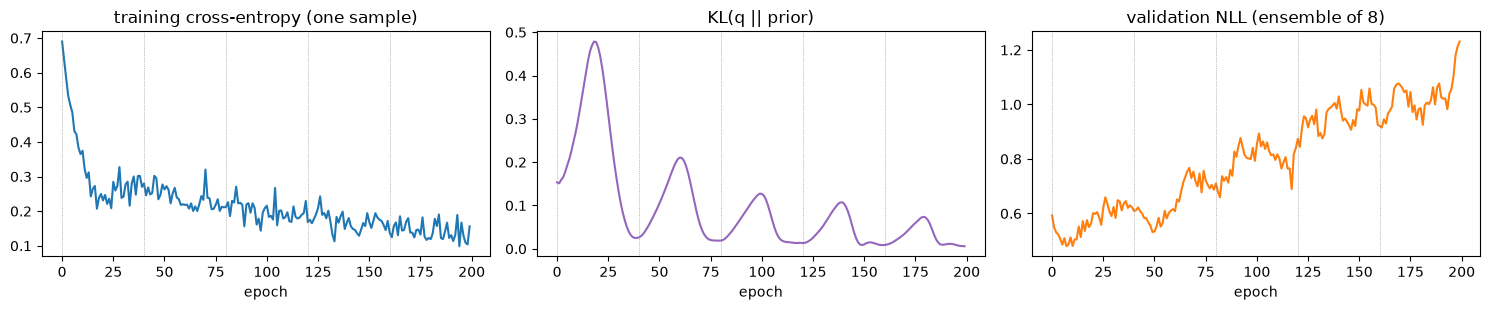

In [6]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)


# =====================================================================
# ELBO training loop (mirrors BayesSheafLightningModule)
# =====================================================================
def accuracy(probs_or_logits, mask):
    return (probs_or_logits[mask].argmax(-1) == y[mask]).float().mean().item()


def train_bsnn(seed, epochs=200):
    set_seed(seed)
    model = bsnn_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    log, best_nll, best_state = [], float("inf"), None
    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        ce = F.cross_entropy(model(data.x, data.edge_index)[train_mask], y[train_mask])
        kl = model.kl_loss()
        beta = kl_beta(epoch)
        (ce + beta * kl).backward()
        optimizer.step()

        model.eval()
        mean_probs = model.predict_proba(data.x, data.edge_index, num_samples=8).mean(0)
        val_nll = F.nll_loss(
            mean_probs[val_mask].clamp_min(1e-8).log(), y[val_mask]
        ).item()
        log.append({"ce": ce.item(), "kl": kl.item(), "beta": beta, "val_nll": val_nll})
        if val_nll < best_nll:
            best_nll, best_state = val_nll, copy.deepcopy(model.state_dict())
    assert best_state is not None, "No finite validation score; check epochs and loss"
    model.load_state_dict(best_state)
    model.eval()
    return model, log


def train_nsd(seed, epochs=200):
    set_seed(seed)
    model = NSDModel(
        4, 2, stalk_dim=2, hidden_dim=8, num_layers=2, variant=NSDVariant.DIAGONAL
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=5e-4)
    best_nll, best_state = float("inf"), None
    for _ in range(epochs):
        model.train()
        optimizer.zero_grad()
        F.cross_entropy(
            model(data.x, data.edge_index)[train_mask], y[train_mask]
        ).backward()
        optimizer.step()
        model.eval()
        with torch.no_grad():
            nll = F.cross_entropy(
                model(data.x, data.edge_index)[val_mask], y[val_mask]
            ).item()
        if nll < best_nll:
            best_nll, best_state = nll, copy.deepcopy(model.state_dict())
    assert best_state is not None, "No finite validation score; check epochs and loss"
    model.load_state_dict(best_state)
    return model.eval()


bsnn_runs = [train_bsnn(seed) for seed in (0, 1, 2)]
nsd_runs = [train_nsd(seed) for seed in (0, 1, 2)]
bsnn_acc = [
    accuracy(
        m.predict_proba(data.x, data.edge_index, num_samples=32).mean(0), test_mask
    )
    for m, _ in bsnn_runs
]
with torch.no_grad():
    nsd_acc = [accuracy(m(data.x, data.edge_index), test_mask) for m in nsd_runs]

print("--- Test accuracy (3 seeds) ---")
print(f"BSNN (ensemble of 32): {np.mean(bsnn_acc):.3f} +/- {np.std(bsnn_acc):.3f}")
print(f"NSD (deterministic):   {np.mean(nsd_acc):.3f} +/- {np.std(nsd_acc):.3f}")

model, log = bsnn_runs[0]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
axes[0].plot([r["ce"] for r in log])
axes[0].set(title="training cross-entropy (one sample)", xlabel="epoch")
axes[1].plot([r["kl"] for r in log], color="tab:purple")
axes[1].set(title="KL(q || prior)", xlabel="epoch")
axes[2].plot([r["val_nll"] for r in log], color="tab:orange")
axes[2].set(title="validation NLL (ensemble of 8)", xlabel="epoch")
for ax in axes:
    for start in range(0, len(log), 40):
        ax.axvline(start, color="gray", lw=0.5, ls=":")
plt.tight_layout()
plt.show()

The dotted lines mark the start of each annealing cycle, where $\beta_t$ drops back to 0. The KL curve shows the tug of war: while $\beta_t$ is small, the data pulls the posterior away from the prior and the KL grows; when $\beta_t$ reaches 1, the KL term pushes back.

**Reading the accuracy.** On this small graph the BSNN is typically *less* accurate than the deterministic NSD. Every prediction averages over sheaves drawn from a posterior that is still broad (Section 7.4 measures how broad): 64 labelled nodes cannot pin down a distribution over roughly 900 restriction maps, and the sampling noise costs accuracy. Exercise 1 shows that lowering the KL weight helps only partly. Accuracy is not the selling point of the Bayesian model, though. The question is whether its predictions **know when they are unsure**, which the next section tests.

<a id="7-interpretation"></a>
# 7. Interpreting Bayesian Sheaves

<a id="test-uncertainty"></a>
### 7.1 Uncertainty on Test Nodes

We draw 64 sheaves from the trained posterior, compute the three uncertainty measures per test node, and plot entropy against epistemic variance, the view used in the paper (shown below for real datasets). Nodes are coloured by whether the ensemble prediction is correct.

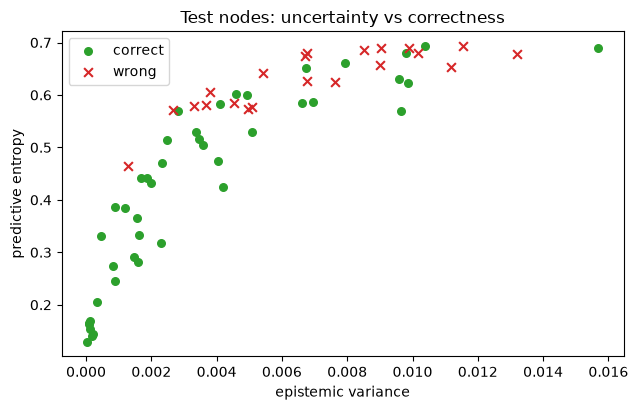

           entropy   mutual info   nodes
correct      0.430        0.0103      43
wrong        0.629        0.0152      21


In [7]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Per-node uncertainty from 64 posterior samples
# =====================================================================
set_seed(123)
ens = model.predict_proba(data.x, data.edge_index, num_samples=64)  # [T, N, C]
mean_probs = ens.mean(0)
entropy = predictive_entropy(mean_probs)
epi_var = epistemic_variance(ens)
mi = mutual_information(ens)
correct = mean_probs.argmax(-1) == y

t = test_mask
fig, ax = plt.subplots(figsize=(6.5, 4.2))
ax.scatter(
    epi_var[t & correct], entropy[t & correct], c="tab:green", s=30, label="correct"
)
ax.scatter(
    epi_var[t & ~correct],
    entropy[t & ~correct],
    c="tab:red",
    marker="x",
    s=40,
    label="wrong",
)
ax.set(
    xlabel="epistemic variance",
    ylabel="predictive entropy",
    title="Test nodes: uncertainty vs correctness",
)
ax.legend()
plt.tight_layout()
plt.show()

print(f"{'':<8}{'entropy':>10}{'mutual info':>14}{'nodes':>8}")
for name, m in [("correct", t & correct), ("wrong", t & ~correct)]:
    print(f"{name:<8}{entropy[m].mean():>10.3f}{mi[m].mean():>14.4f}{int(m.sum()):>8}")

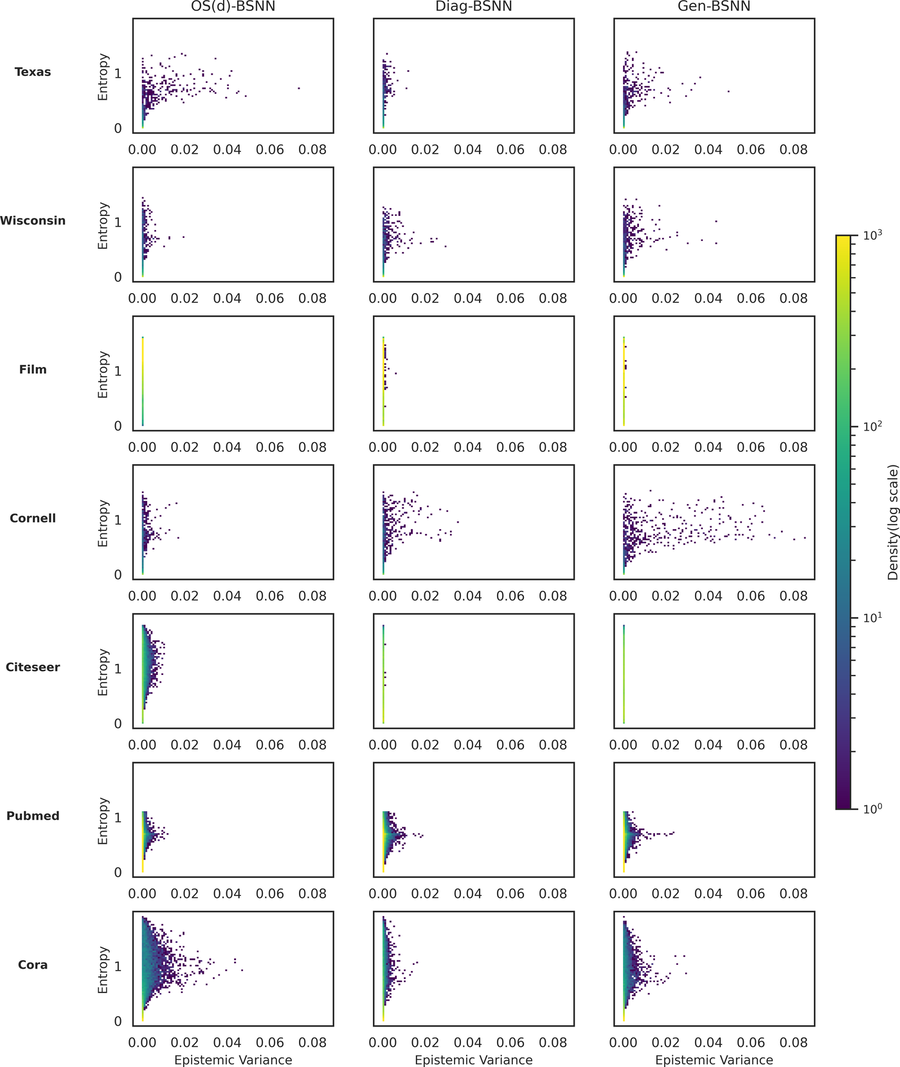

*Predictive entropy versus epistemic variance of the nodes of seven benchmark datasets for orthogonal, diagonal, and general BSNN models (colour = density, log scale). Most nodes have low epistemic variance, while a minority of uncertain nodes spreads to the right.*

<sub>Source: Gillespie et al. (2025), *Bayesian Sheaf Neural Networks*, [arXiv:2410.09590](https://arxiv.org/abs/2410.09590), Fig. 3. Reproduced for teaching with attribution (CC BY-NC-SA 4.0).</sub>

<a id="useful-uncertainty"></a>
### 7.2 Is the Uncertainty Useful?

Uncertainty is useful if it **ranks** predictions: the model should be more often right on the nodes it is confident about. **Selective prediction** makes this concrete. We sort the test nodes by predictive entropy, keep only the most confident fraction, and measure accuracy on what is kept. A rising curve means the uncertainty carries real information, and a flat curve means it does not. We also report the **expected calibration error** (ECE), the average gap between confidence and accuracy. With fewer than 70 test nodes, treat the ECE as a rough indication.

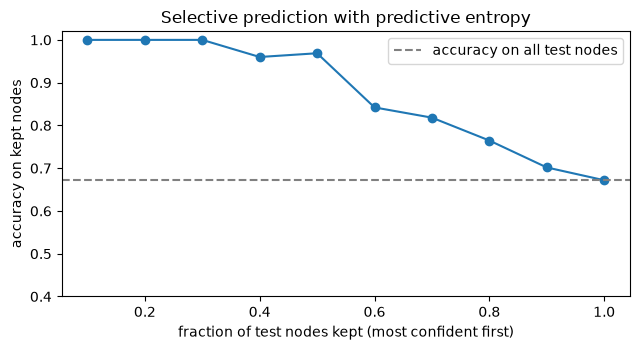

ECE on test nodes: 0.135


In [8]:
# =====================================================================
# Accuracy-coverage curve and calibration
# =====================================================================
test_idx = t.nonzero().flatten()
order = test_idx[entropy[test_idx].argsort()]  # most confident first
coverage = np.linspace(0.1, 1.0, 10)
acc_at = [
    correct[order[: max(1, int(c * len(order)))]].float().mean().item()
    for c in coverage
]

fig, ax = plt.subplots(figsize=(6.5, 3.6))
ax.plot(coverage, acc_at, marker="o")
ax.axhline(
    correct[t].float().mean().item(),
    color="gray",
    ls="--",
    label="accuracy on all test nodes",
)
ax.set(
    xlabel="fraction of test nodes kept (most confident first)",
    ylabel="accuracy on kept nodes",
    title="Selective prediction with predictive entropy",
    ylim=(0.4, 1.02),
)
ax.legend()
plt.tight_layout()
plt.show()
print(
    f"ECE on test nodes: {expected_calibration_error(mean_probs[t], y[t], n_bins=10).item():.3f}"
)

<a id="corrupted-inputs"></a>
### 7.3 Corrupted Inputs

A model that knows what it does not know should become more uncertain on inputs unlike its training data. We replace the features of half of the test nodes with large random noise (5 times the training scale) and compare the uncertainty of corrupted and clean test nodes. The graph and the model are unchanged.

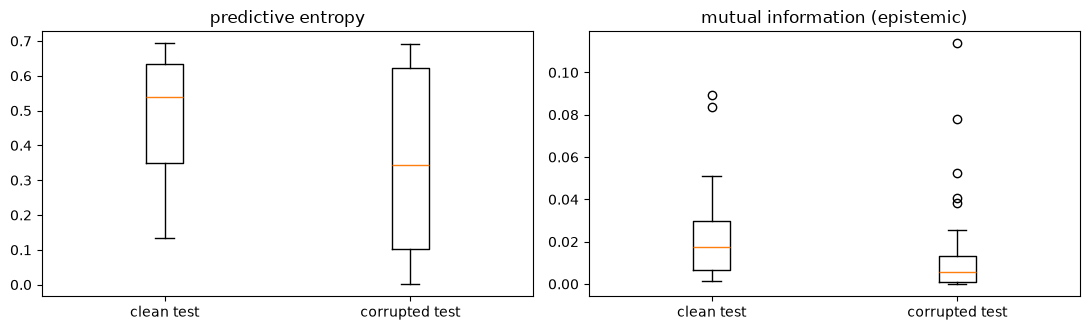

mean entropy  clean 0.474 | corrupted 0.352
mean MI       clean 0.0225 | corrupted 0.0152
accuracy      clean 0.625 | corrupted 0.344


In [9]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Uncertainty on clean vs corrupted test nodes
# =====================================================================
set_seed(7)
corrupted = torch.zeros(n, dtype=torch.bool)
corrupted[test_idx[torch.randperm(len(test_idx))[: len(test_idx) // 2]]] = True
x_corrupt = data.x.clone()
x_corrupt[corrupted] = 5.0 * torch.randn(int(corrupted.sum()), 4)

ens_c = model.predict_proba(x_corrupt, data.edge_index, num_samples=64)
ent_c, mi_c = predictive_entropy(ens_c.mean(0)), mutual_information(ens_c)
clean = t & ~corrupted

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, values, title in [
    (axes[0], ent_c, "predictive entropy"),
    (axes[1], mi_c, "mutual information (epistemic)"),
]:
    ax.boxplot([values[clean].numpy(), values[corrupted].numpy()])
    ax.set_xticks([1, 2], ["clean test", "corrupted test"])
    ax.set(title=title)
plt.tight_layout()
plt.show()
print(
    f"mean entropy  clean {ent_c[clean].mean():.3f} | corrupted {ent_c[corrupted].mean():.3f}"
)
print(
    f"mean MI       clean {mi_c[clean].mean():.4f} | corrupted {mi_c[corrupted].mean():.4f}"
)
print(
    f"accuracy      clean {accuracy(ens_c.mean(0), clean):.3f} | corrupted {accuracy(ens_c.mean(0), corrupted):.3f}"
)

**An instructive failure.** Ideally the **mutual information** would rise on the corrupted nodes, with the sampled sheaves disagreeing on inputs they have never seen. In this toy setting it typically does not: the corrupted nodes become *more* confident and are mostly misclassified. The reason is structural. BSNN is Bayesian only over the **sheaf**. The encoder and decoder are point estimates, so a feature vector five times larger than usual produces large, saturated activations whatever sheaf is sampled. The samples then agree, and both entropy and mutual information drop. Uncertainty about the *geometry* is not uncertainty about the *inputs*. Detecting such inputs needs a model that is also uncertain about its feature pipeline (deep ensembles, MC dropout) or an explicit out-of-distribution detector. The selective-prediction curve above shows where BSNN's uncertainty *is* informative: ranking in-distribution predictions.

<a id="posterior-maps"></a>
### 7.4 The Posterior over Restriction Maps

The uncertainty lives in the sheaf, so we can inspect it there. For the diagonal variant, the learner outputs a posterior mean $\tanh(\boldsymbol{\mu})$ and log-variance per incidence. Row $i$ of the learner's output belongs to the incidence (source of edge $i$) $\trianglelefteq e_i$, and `reverse_edge_permutation` finds the row of the other endpoint. From these we compute, per edge:
* the **posterior-mean transport alignment** $a_e$ between the two endpoint maps (as in notebooks 1 and 2): positive means "carry features over", negative means "flip them";
* the **posterior standard deviation** of the maps, i.e. how unsure the model is about that edge's geometry.

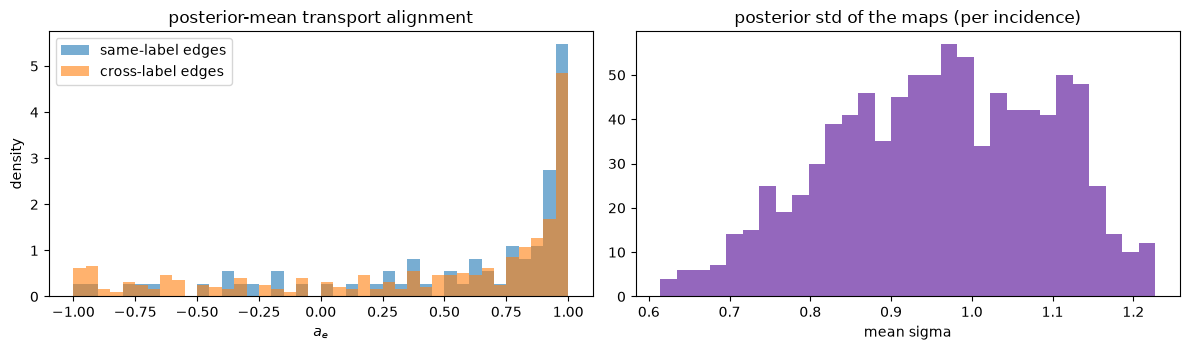

mean alignment: same-label +0.554 | cross-label +0.412
posterior std:  median 0.966 (prior std = 1.0)


In [10]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Posterior mean and spread of the diagonal restriction maps
# =====================================================================
with torch.no_grad():
    x_feat = F.elu(model.encoder(data.x))  # as in BSNNModel.forward (eval mode)
    params = model.sheaf_learner(x_feat, data.edge_index)
    post_mean, log_var = model.sheaf_learner._transform(
        params
    )  # tanh(mu), log sigma^2 per incidence
rev = reverse_edge_permutation(data.edge_index, n)
w_src, w_dst = post_mean, post_mean[rev]
alignment = (
    (w_src * w_dst).sum(-1) / (w_src.norm(dim=-1) * w_dst.norm(dim=-1)).clamp_min(1e-12)
).numpy()
post_std = (0.5 * log_var).exp().mean(-1).numpy()

src_i, dst_i = data.edge_index
same = (y[src_i] == y[dst_i]).numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
bins = np.linspace(-1, 1, 41)
axes[0].hist(
    alignment[same], bins=bins, alpha=0.6, density=True, label="same-label edges"
)
axes[0].hist(
    alignment[~same], bins=bins, alpha=0.6, density=True, label="cross-label edges"
)
axes[0].set(
    title="posterior-mean transport alignment", xlabel="$a_e$", ylabel="density"
)
axes[0].legend()
axes[1].hist(post_std, bins=30, color="tab:purple")
axes[1].set(title="posterior std of the maps (per incidence)", xlabel="mean sigma")
plt.tight_layout()
plt.show()
print(
    f"mean alignment: same-label {alignment[same].mean():+.3f} | cross-label {alignment[~same].mean():+.3f}"
)
print(f"posterior std:  median {np.median(post_std):.3f} (prior std = 1.0)")

A posterior standard deviation far below the prior's value of 1 means the data has pinned the maps down; values near 1 mean the posterior has stayed close to the prior, so that part of the geometry is essentially unconstrained. Comparing the alignment of same-label and cross-label edges tests, once more, whether the learned sheaf follows the heterophily of the graph. Here the comparison applies to the *mean* sheaf, and every sampled sheaf scatters around it.

<a id="how-many-samples"></a>
### 7.5 How Many Samples?

The ensemble prediction is a Monte Carlo estimate, so its error shrinks like $1/\sqrt{T}$. We take a 512-sample prediction as the reference and measure how far smaller ensembles are from it. This tells you how large `ensemble_size` must be for stable predictions and uncertainty estimates.

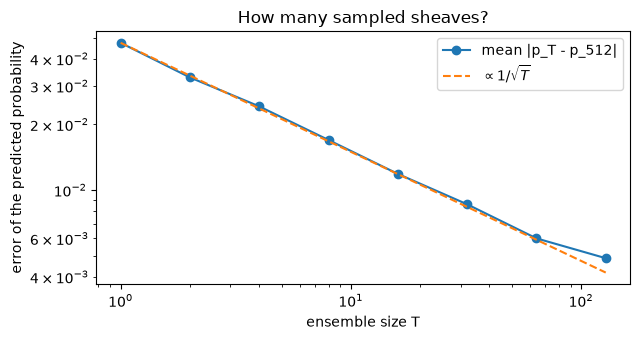

In [11]:
assert isinstance(data, Data)
assert isinstance(data.x, torch.Tensor)
assert isinstance(data.y, torch.Tensor)
assert isinstance(data.edge_index, torch.Tensor)
# =====================================================================
# Monte Carlo error of the ensemble mean
# =====================================================================
set_seed(0)
reference = model.predict_proba(data.x, data.edge_index, num_samples=512).mean(0)
sizes = [1, 2, 4, 8, 16, 32, 64, 128]
errors = []
for T in sizes:
    trials = [
        (
            model.predict_proba(data.x, data.edge_index, num_samples=T).mean(0)
            - reference
        )
        .abs()
        .max(-1)
        .values.mean()
        .item()
        for _ in range(5)
    ]
    errors.append(np.mean(trials))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ax.loglog(sizes, errors, marker="o", label="mean |p_T - p_512|")
ax.loglog(sizes, errors[0] / np.sqrt(sizes), "--", label=r"$\propto 1/\sqrt{T}$")
ax.set(
    xlabel="ensemble size T",
    ylabel="error of the predicted probability",
    title="How many sampled sheaves?",
)
ax.legend()
plt.tight_layout()
plt.show()

<a id="8-exercises"></a>
# 8. Configuration, Reproducibility, and Exercises

**Using it on real data.** BSNN is the `BSNN` model type (and `HET_BSNN` for heterogeneous graphs). The runner switches to `BayesSheafLightningModule`, which trains with the annealed ELBO and evaluates with an ensemble:

```bash
sheaf run --preset texas_bsnn_diagonal
sheaf run --preset texas_bsnn_orthogonal --model.ensemble-size 32 --model.kl-cycle 40
sheaf run --preset cora_bsnn_general --model.kl-anneal constant --model.kl-weight 0.1
```

Record the seed, the variant, `ensemble_size`, and the KL settings. Because predictions are stochastic, also fix and report the number of evaluation samples.

**Key takeaways**
* BSNN learns a *distribution* over sheaves; every layer and every forward pass uses a fresh sample.
* The ELBO balances fitting the labels against staying close to a prior; cyclical annealing prevents early posterior collapse.
* Entropy measures total uncertainty; mutual information and epistemic variance isolate the part caused by uncertainty about the geometry.
* Whether uncertainty is useful is an empirical question: check selective prediction, corrupted inputs, calibration, and the posterior over maps.

### Hands-on Exercises
1. **KL weight.** Train with `kl_beta` fixed at 0 (no KL) and at 1 (no annealing). How do accuracy, calibration, and the posterior std change?
2. **Fewer labels.** Reduce the training split to 10%. Does the BSNN's advantage in calibration or selective prediction grow?
3. **Orthogonal posteriors.** Switch to `BSNNVariant.ORTHOGONAL` (it requires `stalk_dim >= 2`). How would you measure the spread of a distribution over rotations?
4. **Uncertainty on the graph.** Plot the mutual information of every node on the graph layout. Is it higher near training nodes, or near heterophilic edges?